# Feature EDA: PLAID Appliance Features
### EC5203 Machine Learning · Group 6 – Team Plug Detectives

**Goal:** check the 30 candidate features from `02_feature_extraction` before modelling:
are they physically sensible, missing, near-constant or redundant?
This is stage 1 of the feature funnel (30 → about 20 → best 15 in `04_modelling`).

**Rule:** after Step 2, every decision uses the **development homes only**; the test homes stay unseen.

## 1. Setup and first look
`features.csv` has three kinds of columns:
- **Info** (not features): id, type (label), location (for the grouped split), status, time, length, EDA flags.
- **Window flags** (not features): stable_found, window_ok, spike_in_window.
- **30 candidate features.**

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path.home() / "Documents" / "10084619"
features = pd.read_csv(DATA / "features.csv")

INFO = ["id", "type", "location", "status", "collection_time", "length_s",
        "flag_short", "flag_low_state", "flag_spike", "flag_low_amp"]
FLAGS = ["stable_found", "window_ok", "spike_in_window"]
feature_cols = [c for c in features.columns if c not in INFO + FLAGS]

print(features.shape, "|", len(feature_cols), "features")
print(features["type"].nunique(), "types |", features["location"].nunique(), "homes")
display(features[feature_cols].describe().T.round(3))

(1810, 43) | 30 features
11 types | 56 homes


,count,mean,std,min,25%,50%,75%,max
i_rms,1810.0,2.425,3.181,0.030,0.282,0.557,4.157,13.210
i_peak,1810.0,4.099,5.152,0.057,0.520,1.150,6.705,22.580
p_w,1810.0,259.065,357.140,0.308,23.607,58.771,419.953,1648.938
q_var,1810.0,94.586,151.709,0.641,10.452,26.402,91.364,846.959
pf,1810.0,0.817,0.220,0.080,0.575,0.935,0.989,1.000
dpf,1810.0,0.912,0.134,0.371,0.882,0.979,0.996,1.000
phase_deg,1810.0,3.735,24.426,-68.215,-3.938,5.769,16.732,64.840
crest_factor,1810.0,2.142,1.196,1.333,1.441,1.558,2.115,15.613
form_factor,1810.0,1.300,0.331,1.078,1.111,1.131,1.241,3.231
skewness,1810.0,-0.002,0.174,-3.197,-0.001,0.001,0.007,1.102


## 2. Hold out the test homes

The final test set = ~20% of **homes** (not recordings), chosen with `StratifiedGroupKFold`:
- **Group** = location, so a home is entirely in dev or entirely in test (no appliance on both sides).
- **Stratified**, so all 11 types appear in both parts with similar proportions.
- `random_state=42`, so the split is the same every run. It is never changed after seeing results.

The split is saved to `split.csv` (id, location, split) for `04_modelling`.
**From here on, the analysis uses the development homes (`dev`) only.**

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(sgkf.split(features, features["type"], groups=features["location"]))

test_homes = sorted(features["location"].iloc[test_idx].unique())
features["split"] = np.where(features["location"].isin(test_homes), "test", "dev")
features[["id", "location", "split"]].to_csv(DATA / "split.csv", index=False)

dev = features[features["split"] == "dev"].copy()
test = features[features["split"] == "test"]

# Checks
print("Test homes:", test_homes)
print(f"dev: {len(dev)} recordings, {dev['location'].nunique()} homes | "
      f"test: {len(test)} recordings ({len(test) / len(features):.0%}), {test['location'].nunique()} homes")
print("Homes in both parts:", set(dev["location"]) & set(test["location"]))

ct = pd.crosstab(features["type"], features["split"])
ct["test %"] = (100 * ct["test"] / (ct["dev"] + ct["test"])).round(0)
display(ct)

Test homes: ['house10', 'house14', 'house22', 'house32', 'house34', 'house40', 'house42', 'house53', 'house8', 'house9']
dev: 1447 recordings, 46 homes | test: 363 recordings (20%), 10 homes
Homes in both parts: set()


split,dev,test,test %
type,,,
Air Conditioner,151,53,26.0
Compact Fluorescent Lamp,185,45,20.0
Fan,185,35,16.0
Fridge,83,25,23.0
Hairdryer,196,50,20.0
Heater,71,14,16.0
Incandescent Light Bulb,128,29,18.0
Laptop,162,40,20.0
Microwave,159,41,20.0


## 3. Missing values (dev only)

Before filling gaps (imputation, done later inside the `04` pipeline), check:
1. **How much** is missing per feature. Rule of thumb: drop a feature if more than 30% is missing.
2. **Where**: is it spread evenly, or concentrated in some appliance types?
3. **Why**: random gaps, or structural ones (caused by what the appliance *is* or how it was *recorded*)?

We **don't fill anything here**. Filling uses medians, and medians must be learned from training folds only.

In [3]:
# 3a. How much is missing per feature (dev only)
na_pct = dev[feature_cols].isna().mean().mul(100).sort_values(ascending=False)
missing = na_pct[na_pct > 0].round(1)
print("Features with missing values (% of dev recordings):")
print(missing.to_string())
print(f"\nRecordings with at least one NaN: {dev[feature_cols].isna().any(axis=1).sum()} of {len(dev)}\n")

# 3b. Where it is missing: % missing per appliance type
by_type = dev[missing.index].isna().groupby(dev["type"]).mean().mul(100).round(1)
display(by_type[["vi_curvature", "inrush_ratio"]].rename(columns={"inrush_ratio": "transient (all 4)"}))

# 3c. Check the two causes
transient = ["inrush_ratio", "settling_time", "transient_energy", "inrush_duration"]
print("\nTransient NaNs always together:", dev[transient].isna().nunique(axis=1).eq(1).all())
print("vi_curvature NaN exactly when |vi_mid_slope| <= 0.3:",
      dev["vi_curvature"].isna().equals(dev["vi_mid_slope"].abs() <= 0.3))

Features with missing values (% of dev recordings):
vi_curvature        28.3
inrush_duration     12.9
transient_energy    12.9
settling_time       12.9
inrush_ratio        12.9

Recordings with at least one NaN: 468 of 1447



,vi_curvature,transient (all 4)
type,,
Air Conditioner,1.3,3.3
Compact Fluorescent Lamp,100.0,1.6
Fan,0.0,7.6
Fridge,0.0,20.5
Hairdryer,0.0,2.6
Heater,0.0,8.5
Incandescent Light Bulb,0.0,3.1
Laptop,100.0,74.7
Microwave,28.3,1.9



Transient NaNs always together: True
vi_curvature NaN exactly when |vi_mid_slope| <= 0.3: True


## 4. Distributions per appliance type + physics checks (dev only)

Does each feature behave as physics predicts for each appliance type?
- **Resistive** (heater, bulb, hairdryer): current is a clean sine in step with voltage, so pf ≈ 1, THD ≈ 0 and crest factor = √2.
- **Electronic** (CFL, laptop): a rectifier plus capacitor draws spiky current pulses, so THD is high, crest factor is high and conduction angle is short.
- **Motors** (fridge, washing machine): coils make the current **lag** the voltage, so phase < 0.

We use **medians** (not means), because a few extreme values (inrush up to 233) would pull a mean far off.

,p_w,pf,phase_deg,thd,h3_h1,crest_factor,conduction_angle,vi_area,inrush_ratio
type,,,,,,,,,
Air Conditioner,53.17,0.98,-0.51,0.10,0.08,1.45,0.96,0.52,1.66
Compact Fluorescent Lamp,7.72,0.50,38.12,1.20,0.85,3.51,0.41,0.54,16.36
Fan,40.09,0.95,6.17,0.06,0.05,1.45,0.96,0.92,1.21
Fridge,207.52,0.91,-21.09,0.07,0.06,1.57,0.96,1.10,2.07
Hairdryer,380.39,0.99,5.39,0.06,0.03,1.42,0.97,0.28,1.10
Heater,661.33,1.00,4.16,0.04,0.02,1.40,0.97,0.26,1.04
Incandescent Light Bulb,35.98,0.98,10.87,0.03,0.02,1.44,0.95,0.58,6.77
Laptop,22.35,0.51,17.96,1.47,0.94,4.02,0.27,0.25,5.42
Microwave,578.63,0.91,-4.83,0.40,0.36,1.89,0.96,0.31,2.15


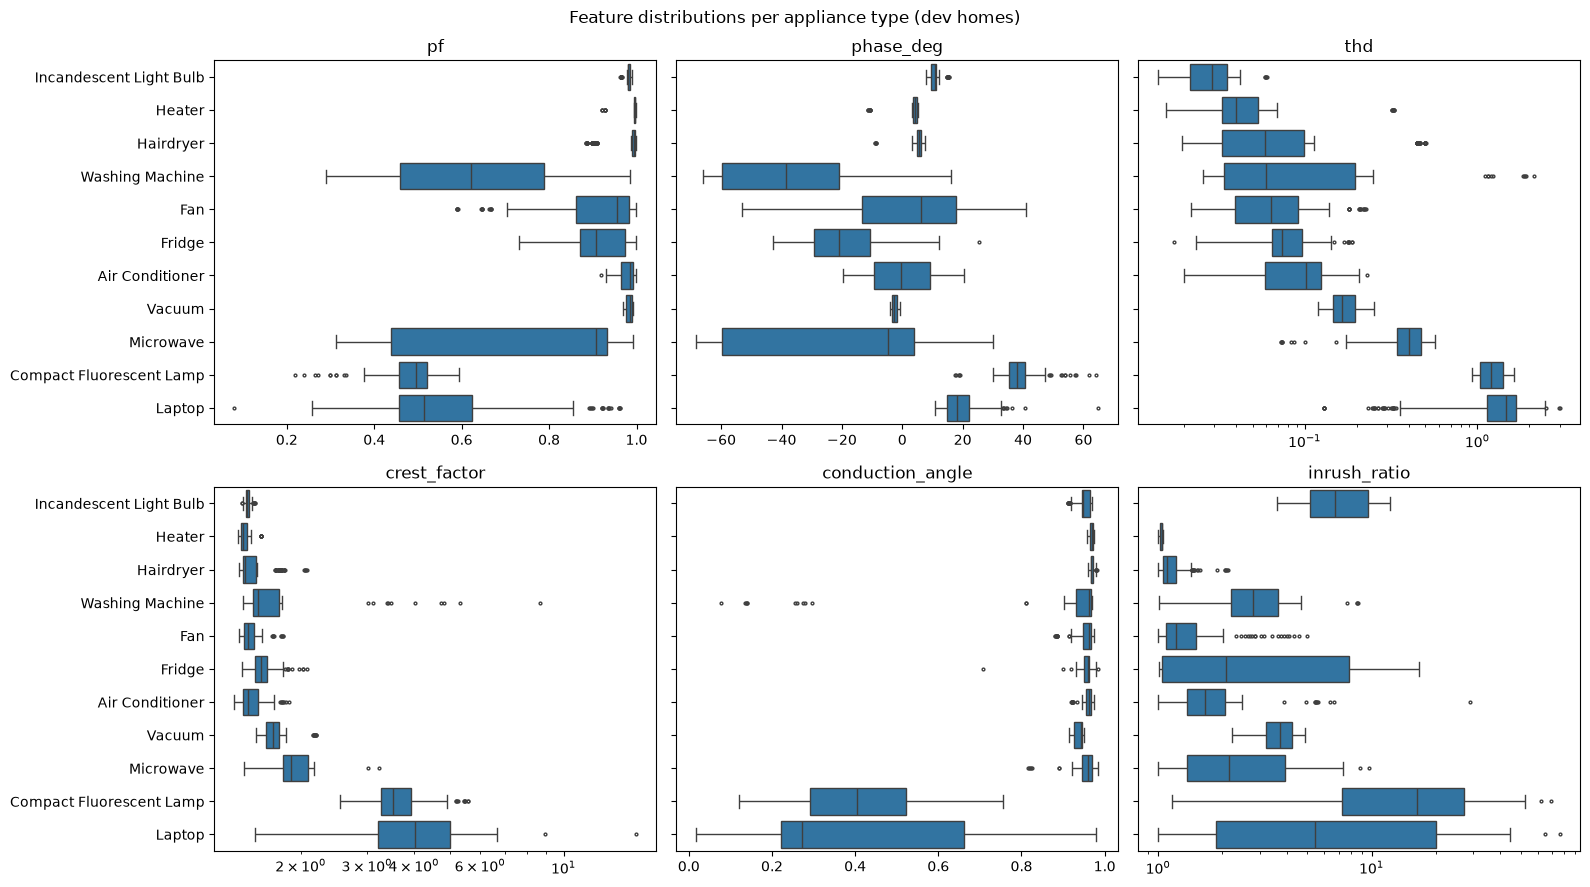

In [4]:
# 4a. Median of each feature per appliance type
KEY = ["p_w", "pf", "phase_deg", "thd", "h3_h1", "crest_factor",
       "conduction_angle", "vi_area", "inrush_ratio"]
med = dev.groupby("type")[feature_cols].median()
display(med[KEY].round(2))

# 4b. Boxplots: how spread out is each type, and do types overlap?
PLOT = ["pf", "phase_deg", "thd", "crest_factor", "conduction_angle", "inrush_ratio"]
LOG = ["thd", "crest_factor", "inrush_ratio"]
order = med["thd"].sort_values().index   # cleanest sine at the top, most distorted at the bottom

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, col in zip(axes.flat, PLOT):
    sns.boxplot(data=dev, x=col, y="type", order=order, ax=ax, fliersize=2)
    if col in LOG:
        ax.set_xscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Feature distributions per appliance type (dev homes)")
plt.tight_layout()
plt.show()

In [5]:
# 4c. Do the medians match physics?
resistive = ["Heater", "Incandescent Light Bulb", "Hairdryer"]
electronic = ["Compact Fluorescent Lamp", "Laptop"]
motors = ["Fridge", "Washing Machine"]
r, e, m = med.loc[resistive], med.loc[electronic], med.loc[motors]

checks = {
    "Resistive: pf > 0.95 and THD < 0.1":               ((r["pf"] > 0.95) & (r["thd"] < 0.1)).all(),
    "Resistive: crest factor = sqrt(2) (clean sine)":   np.allclose(r["crest_factor"], np.sqrt(2), atol=0.05),
    "Electronic: THD > 1, crest > 3, conduction < 0.5": ((e["thd"] > 1) & (e["crest_factor"] > 3) & (e["conduction_angle"] < 0.5)).all(),
    "Motors: current lags voltage (phase < 0)":         (m["phase_deg"] < 0).all(),
    "Bulb inrush > heater inrush (cold filament)":      med.loc["Incandescent Light Bulb", "inrush_ratio"] > med.loc["Heater", "inrush_ratio"],
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "|", name)

# 4d. Two features measured in different ways should agree: V-I area = pi * |sin(phase)| for sine-like current
sine = dev[dev["thd"] < 0.1]
expected = np.pi * np.abs(np.sin(np.radians(sine["phase_deg"])))
print(f"\nV-I area vs phase, {len(sine)} near-sine recordings: "
      f"correlation = {np.corrcoef(expected, sine['vi_area'])[0, 1]:.3f}")

PASS | Resistive: pf > 0.95 and THD < 0.1
PASS | Resistive: crest factor = sqrt(2) (clean sine)
PASS | Electronic: THD > 1, crest > 3, conduction < 0.5
PASS | Motors: current lags voltage (phase < 0)
PASS | Bulb inrush > heater inrush (cold filament)

V-I area vs phase, 668 near-sine recordings: correlation = 0.998


## 5. Outliers (dev only)

An outlier is **real** (an unusual model or mode, which the model should learn) or **bad** (a broken recording).
- **Rule:** a value is a *far outlier* if it lies more than **3 × IQR** outside the middle 50% **of its own type**.
  (IQR = Q3 − Q1. Boxplot dots use 1.5 × IQR; 3 × IQR means "really far".)
- Count far outliers per feature and per recording, then **look at the waveforms** of the most unusual ones.
- Delete nothing yet. Flagged recordings get a with/without test in `04`.

In [6]:
# 5a. Far outliers within each type (beyond 3 x IQR from the type's own box)
g = dev.groupby("type")[feature_cols]
q1 = g.transform(lambda s: s.quantile(0.25))
q3 = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
far = (dev[feature_cols] < q1 - 3 * iqr) | (dev[feature_cols] > q3 + 3 * iqr)

print("% of recordings that are far outliers, per feature (top 8):")
print(far.mean().mul(100).round(1).sort_values(ascending=False).head(8).to_string())

# 5b. Which recordings are unusual in many features at once? Are they already flagged?
FLAG_COLS = ["flag_short", "flag_low_state", "flag_spike", "flag_low_amp"]
dev["n_far"] = far.sum(axis=1)
dev["flagged"] = dev[FLAG_COLS].any(axis=1) | ~dev["window_ok"] | dev["spike_in_window"]
many = dev["n_far"] >= 5
print(f"\nRecordings far out in 5+ features: {many.sum()} (already flagged: {dev.loc[many, 'flagged'].sum()})")
display(dev.nlargest(8, "n_far")[["id", "type", "status", "location", "n_far", "i_rms", "p_w", "flagged"]].round(2))

% of recordings that are far outliers, per feature (top 8):
skewness           10.2
inrush_duration     6.5
hf_noise_ratio      6.0
h2_h1               5.5
cycle_stability     4.4
thd                 4.1
h3_h1               4.0
pf                  3.5

Recordings far out in 5+ features: 66 (already flagged: 15)


,id,type,status,location,n_far,i_rms,p_w,flagged
123,124,Heater,off-on,house7,16,11.01,1203.65,False
125,126,Heater,off-on,house7,16,10.99,1199.97,False
127,128,Heater,off-on,house7,16,10.95,1188.81,False
1240,1246,Hairdryer,noheat,house3,16,0.27,28.72,True
1580,1586,Washing Machine,off-on,house7,16,0.20,6.84,True
1237,1243,Hairdryer,noheat,house3,15,0.26,28.14,True
1151,1157,Heater,low,house2,14,5.23,580.51,False
1152,1158,Heater,low,house2,14,5.23,581.17,False


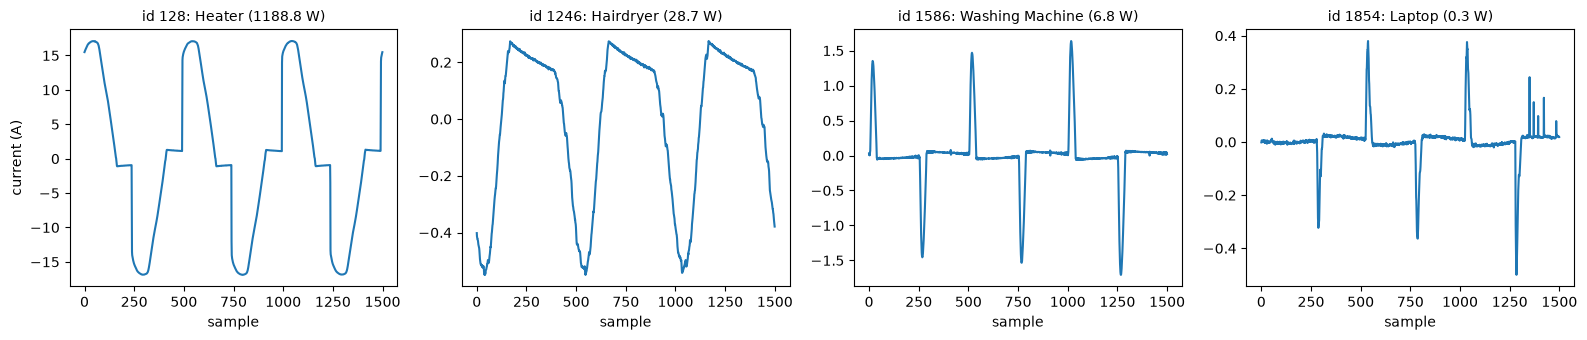

In [7]:
# 5c. Real or bad? Look at the current of 4 of the most unusual recordings
WAVES = DATA / "submetered_new"
EXAMPLES = [128, 1246, 1586, 1854]
info = dev.set_index("id")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, rid in zip(axes, EXAMPLES):
    i = pd.read_csv(WAVES / f"{rid}.csv", header=None)[0].to_numpy()
    ax.plot(i[-1500:])   # last 3 cycles (3 x 500 samples)
    ax.set_title(f"id {rid}: {info.loc[rid, 'type']} ({info.loc[rid, 'p_w']:.1f} W)", fontsize=10)
    ax.set_xlabel("sample")
axes[0].set_ylabel("current (A)")
plt.tight_layout()
plt.show()

## 6. Near-constant and weak features (dev only)

Three checks per feature:
1. **Near-zero variance** (caret rule): near-constant only if **both** the most common value is >19× as frequent as the 2nd **and** <10% of values are unique.
2. **eta²** (from the Kruskal–Wallis test, which works on **ranks** so outliers can't dominate): share of variation explained by appliance type (0 = none, 1 = types fully separated).
3. **Best one-vs-rest AUC**: how well the feature alone picks out its best type (0.5 = coin flip, 1 = perfect).

**Drop** a feature only if it's weak overall **and** isn't a detector for any single type **and** physics explains why.

,unique_%,freq_ratio,eta2,best_auc,best_type,near_constant
feature,,,,,,
skewness,100.000,1.000,0.052,0.667,Compact Fluorescent Lamp,False
vi_curvature,100.000,1.000,0.236,0.905,Vacuum,False
h2_h1,100.000,1.000,0.342,0.855,Microwave,False
vi_area,100.000,1.000,0.412,0.962,Vacuum,False
settling_time,16.257,1.864,0.429,0.942,Laptop,False
v_at_ipeak,100.000,1.000,0.474,0.946,Vacuum,False
cycle_stability,100.000,1.000,0.529,0.923,Laptop,False
dpf,100.000,1.000,0.567,0.957,Vacuum,False
inrush_duration,4.837,3.228,0.569,0.921,Vacuum,False



Near-constant features: []


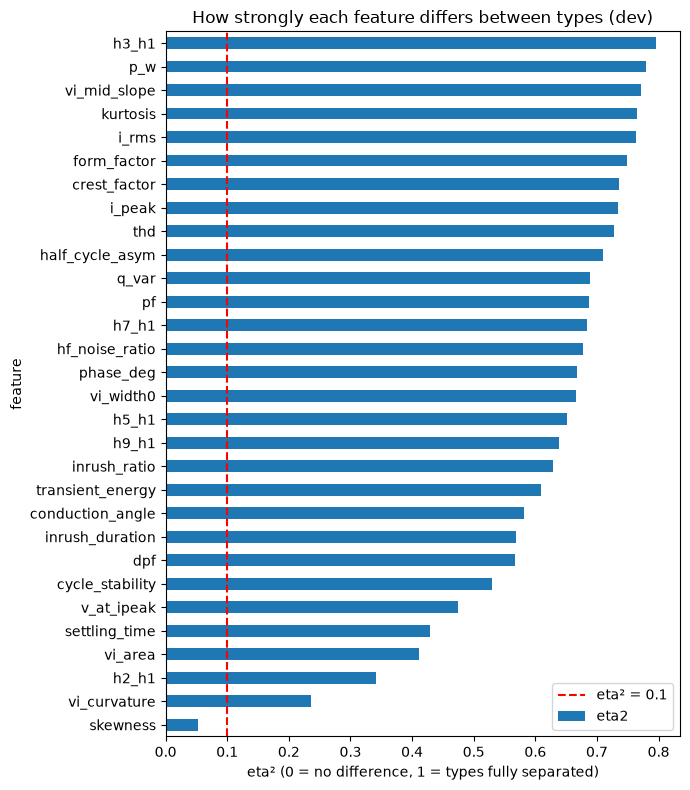

In [8]:
from scipy.stats import kruskal
from sklearn.metrics import roc_auc_score

# 6a. Score each feature: near-constant? differs between types? detects one type?
rows = []
for col in feature_cols:
    d = dev[[col, "type"]].dropna()
    counts = d[col].value_counts()
    H = kruskal(*[g[col] for _, g in d.groupby("type")]).statistic
    k, n = d["type"].nunique(), len(d)
    auc = {t: roc_auc_score(d["type"] == t, d[col]) for t in d["type"].unique()}
    best = max(auc, key=lambda t: abs(auc[t] - 0.5))
    rows.append({"feature": col,
                 "unique_%": 100 * d[col].nunique() / n,
                 "freq_ratio": counts.iloc[0] / counts.iloc[1],
                 "eta2": (H - k + 1) / (n - k),
                 "best_auc": 0.5 + abs(auc[best] - 0.5),
                 "best_type": best})

info6 = pd.DataFrame(rows).set_index("feature").sort_values("eta2").round(3)
info6["near_constant"] = (info6["freq_ratio"] > 19) & (info6["unique_%"] < 10)
display(info6)
print("\nNear-constant features:", info6.index[info6["near_constant"]].tolist())

ax = info6["eta2"].plot.barh(figsize=(7, 8), title="How strongly each feature differs between types (dev)")
ax.axvline(0.1, color="red", ls="--", label="eta² = 0.1")
ax.set_xlabel("eta² (0 = no difference, 1 = types fully separated)")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# 6b. Skewness: medians per type, and hairdryers home by home
print(dev.groupby("type")["skewness"].median().round(3).to_string())
hd = dev[dev["type"] == "Hairdryer"]
print("\nHairdryer skewness by home (2 lowest, 2 highest):")
display(hd.groupby("location")["skewness"].median().round(2).sort_values().iloc[[0, 1, -2, -1]])

# Running list of dropped features (Step 7 will add to it)
dropped = {"skewness": "barely differs between types (eta² 0.05); its sign changes from home to home"}

type
Air Conditioner             0.002
Compact Fluorescent Lamp    0.016
Fan                         0.001
Fridge                      0.000
Hairdryer                   0.000
Heater                     -0.000
Incandescent Light Bulb     0.001
Laptop                      0.006
Microwave                  -0.001
Vacuum                      0.000
Washing Machine            -0.000

Hairdryer skewness by home (2 lowest, 2 highest):


location
house13   -0.73
house50   -0.68
house38    0.67
house29    0.68
Name: skewness, dtype: float64

## 7. Redundancy: features that say the same thing (dev only)

- **Spearman ρ** between every pair of the 29 remaining features (ranks, so curved relationships and outliers are fine).
- A pair with **|ρ| ≥ 0.9** is treated as near-copies. Strongest pair first, drop the one with the **lower eta²** from Step 6 (it separates types less).
- Why 0.9 and not lower? Between 0.8 and 0.9, features are related mainly because they separate the **same groups of types** (e.g. kurtosis vs vi_mid_slope, −0.86) while measuring different physics. Dropping those would lose information.
- Reason: twins split each other's importance in `04`, so removing them makes the importance ranking honest.

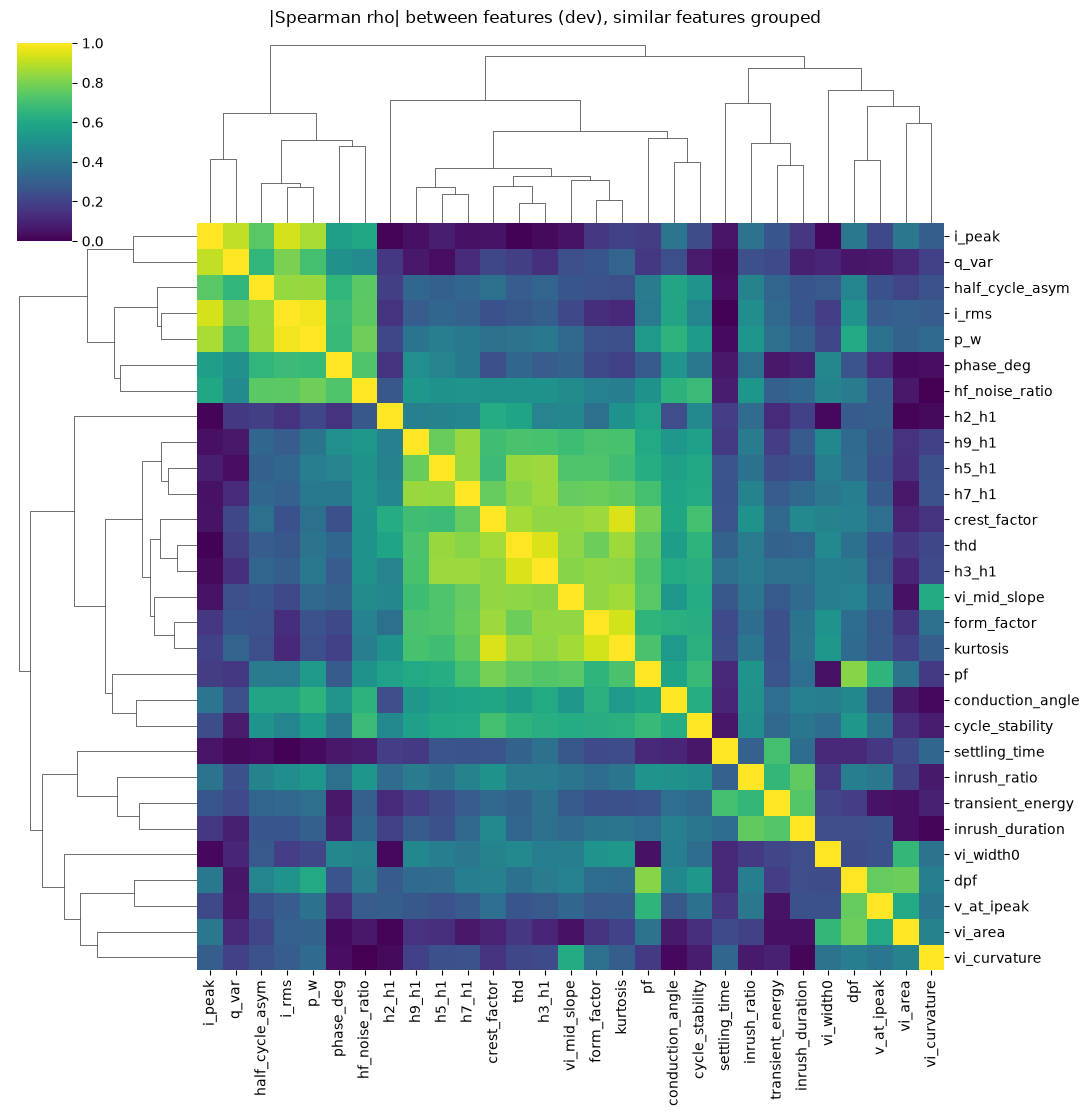

i_rms         p_w         0.978
crest_factor  kurtosis    0.945
thd           h3_h1       0.943
i_rms         i_peak      0.934
form_factor   kurtosis    0.933
i_peak        q_var       0.903

Dropped so far (6):
  skewness        barely differs between types (eta² 0.05); its sign changes from home to home
  i_rms           redundant with p_w (rho 0.98); lower eta²
  crest_factor    redundant with kurtosis (rho 0.95); lower eta²
  thd             redundant with h3_h1 (rho 0.94); lower eta²
  form_factor     redundant with kurtosis (rho 0.93); lower eta²
  q_var           redundant with i_peak (rho 0.90); lower eta²

Features left: 24


In [10]:
# 7a. Spearman correlation between the remaining features (dev only)
keep = [c for c in feature_cols if c not in dropped]
rho = dev[keep].corr(method="spearman")

g = sns.clustermap(rho.abs(), cmap="viridis", vmin=0, vmax=1, figsize=(11, 11))
g.fig.suptitle("|Spearman rho| between features (dev), similar features grouped", y=1.01)
plt.show()

# 7b. Pairs that are near-copies: |rho| >= 0.9, strongest first
upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s.abs() >= 0.9].sort_values(key=abs, ascending=False)
print(pairs.round(3).to_string())

# 7c. For each pair, drop the feature that separates types less (lower eta² from Step 6)
for (a, b), r in pairs.items():
    if a in dropped or b in dropped:
        continue
    loser = a if info6.loc[a, "eta2"] < info6.loc[b, "eta2"] else b
    winner = b if loser == a else a
    dropped[loser] = f"redundant with {winner} (rho {r:.2f}); lower eta²"

keep = [c for c in feature_cols if c not in dropped]
print(f"\nDropped so far ({len(dropped)}):")
for f, why in dropped.items():
    print(f"  {f:15s} {why}")
print(f"\nFeatures left: {len(keep)}")

**Step 7 findings**
- Spearman |ρ| ≥ 0.9 found 6 near-copy pairs, in 3 families: size (i_rms, p_w, i_peak, q_var), peakiness (crest, form, kurtosis) and harmonics (thd, h3).
- Dropped the lower-eta² member of each pair: `i_rms`, `crest_factor`, `thd`, `form_factor`, `q_var`.
- Pairs between 0.8 and 0.9 were kept: they measure different physics but separate the same type groups.
- Features: 29 → 24. Removing twins keeps `04`'s permutation importance honest.

## 8. Flags vs features (dev only)

Two kinds of flags:
- **Recording-quality**: `flag_short`, `no_stable`, `window_bad`, `flag_spike`, `spike_in_window` (something about *how* it was recorded).
- **Appliance-state**: `flag_low_state`, `flag_low_amp` (the appliance may not be in its normal working state).

**Distance** of a recording from its type = the median, over the 24 kept features, of |value − type median| / type IQR
(a "robust z-score": 0 = perfectly typical, 1 = typically one box-width away).
If flagged recordings are **no further** from their type than unflagged ones, the flag doesn't harm the features.

In [11]:
# 8a. How common is each flag, and in which types?
dev["no_stable"] = ~dev["stable_found"]
dev["window_bad"] = ~dev["window_ok"]
ALL_FLAGS = FLAG_COLS + ["no_stable", "window_bad", "spike_in_window"]

print(f"Dev recordings with at least one flag: {dev[ALL_FLAGS].any(axis=1).sum()} of {len(dev)}\n")
display(dev[ALL_FLAGS].groupby(dev["type"]).mean().mul(100).round(1))

# 8b. Are flagged recordings unusual for their type? (robust distance over the 24 kept features)
by_type = dev.groupby("type")[keep]
center = by_type.transform("median")
spread = by_type.transform(lambda s: s.quantile(0.75) - s.quantile(0.25))
dev["distance"] = ((dev[keep] - center) / spread.replace(0, np.nan)).abs().median(axis=1)

summary = pd.DataFrame({
    "n": dev[ALL_FLAGS].sum(),
    "distance_flagged": [dev.loc[dev[f], "distance"].median() for f in ALL_FLAGS],
    "distance_unflagged": [dev.loc[~dev[f], "distance"].median() for f in ALL_FLAGS],
}).round(2)
display(summary)

Dev recordings with at least one flag: 284 of 1447



,flag_short,flag_low_state,flag_spike,flag_low_amp,no_stable,window_bad,spike_in_window
type,,,,,,,
Air Conditioner,6.6,0.0,1.3,0.0,0.0,9.9,0.0
Compact Fluorescent Lamp,5.4,0.0,1.1,8.1,5.4,5.9,0.0
Fan,5.4,0.0,2.7,0.0,1.1,5.4,0.0
Fridge,24.1,9.6,2.4,0.0,15.7,25.3,0.0
Hairdryer,0.0,2.6,1.0,0.0,0.0,0.5,0.0
Heater,0.0,0.0,5.6,0.0,0.0,0.0,0.0
Incandescent Light Bulb,7.0,0.0,3.9,0.0,7.8,7.8,0.0
Laptop,0.6,3.1,1.9,1.2,74.1,0.6,0.6
Microwave,0.0,1.3,0.0,0.0,0.0,0.0,0.0


,n,distance_flagged,distance_unflagged
flag_short,70,0.38,0.42
flag_low_state,48,0.71,0.41
flag_spike,28,0.55,0.42
flag_low_amp,17,0.96,0.42
no_stable,176,0.45,0.42
window_bad,79,0.43,0.42
spike_in_window,1,0.50,0.42


**Step 8 findings**
- 284 of 1,447 dev recordings carry at least one flag.
- **Recording-quality flags** (short, no_stable, window_bad, spike) don't change the features: median distance 0.38–0.55 vs 0.42 unflagged. Keep them.
- **Appliance-state flags** (`flag_low_state` 0.71, `flag_low_amp` 0.96) are about 2× further from their type: standby washing machines, tiny CFL currents. Real states, so keep them; `04` tests training with vs without, and validation/test always keep them.
- **Flags are never model inputs:** `no_stable` covers 74% of laptops, so it would become a "laptop" shortcut that comes from the recording process.

## 9. Summary: the feature shortlist

Final table of the kept features (how well they separate types, what they detect, how much is missing),
saved to `feature_shortlist.json` for `04_modelling`, with the reason for every drop and the to-dos found in Steps 3–8.

In [12]:
import json

# 9a. The final shortlist at a glance
final = info6.loc[keep, ["eta2", "best_auc", "best_type"]].assign(missing_pct=na_pct[keep].round(1))
display(final.sort_values("eta2", ascending=False))

# 9b. Save the shortlist, the drop reasons and the to-dos for 04
shortlist = {
    "features": keep,
    "dropped": dropped,
    "notes_for_04": [
        "Impute NaN with the median inside the pipeline (fit on training folds only); no missing-indicator columns.",
        "Never use flag columns as model inputs.",
        "Sensitivity test 1: train with vs without flag_low_state / flag_low_amp rows (validation keeps all).",
        "Sensitivity test 2: with vs without the 4 transient features.",
        "Hard cases to check in the confusion matrix: Air Conditioner vs Fan; Microwave (two states).",
    ],
}
(DATA / "feature_shortlist.json").write_text(json.dumps(shortlist, indent=2, ensure_ascii=False), encoding="utf-8")

# 9c. Self-check: read the file back and make sure it is right
check = json.loads((DATA / "feature_shortlist.json").read_text(encoding="utf-8"))
assert len(check["features"]) == len(feature_cols) - len(dropped) == 24
assert not set(check["features"]) & set(dropped)
print(f"\nSaved feature_shortlist.json: {len(check['features'])} features kept, {len(dropped)} dropped")

,eta2,best_auc,best_type,missing_pct
feature,,,,
h3_h1,0.795,0.928,Incandescent Light Bulb,0.0
p_w,0.779,0.981,Compact Fluorescent Lamp,0.0
vi_mid_slope,0.772,0.961,Compact Fluorescent Lamp,0.0
kurtosis,0.765,0.920,Laptop,0.0
i_peak,0.734,0.929,Microwave,0.0
half_cycle_asym,0.710,0.905,Compact Fluorescent Lamp,0.0
pf,0.687,0.908,Heater,0.0
h7_h1,0.684,0.904,Laptop,0.0
hf_noise_ratio,0.677,0.991,Compact Fluorescent Lamp,0.0



Saved feature_shortlist.json: 24 features kept, 6 dropped


## Conclusions of 03_feature_eda

| Step | Result |
|---|---|
| 2. Test holdout | 10 test homes (363 recordings) held out; everything after uses 46 dev homes (1,447) |
| 3. Missing values | Only 5 features. `vi_curvature` 28.3% (pulse-type electronics), transient 12.9% (switch-on not recorded) |
| 4. Physics checks | All 5 pass; `vi_area` agrees with `phase_deg` (r = 0.998). Hard cases: AC ≈ Fan, Microwave has 2 states |
| 5. Outliers | Mostly real variety (triac heaters, fan-only hairdryers); broken-looking ones are already flagged |
| 6. Near-constant | None; dropped `skewness` (eta² 0.05, sign changes by home) |
| 7. Redundancy | Dropped 5 near-copies (|ρ| ≥ 0.9): `i_rms`, `crest_factor`, `thd`, `form_factor`, `q_var` |
| 8. Flags | Recording-quality flags don't affect features; state flags do but are real. Flags are never inputs |

**Feature funnel:** 30 → 29 → **24** (saved in `feature_shortlist.json`). The final cut to about 15 happens in `04` with permutation importance.